# Cuaderno 03 · Preparación de tablas ordenadas, estadísticas y figuras

**Expediente:** BES-jun · **Estado del expediente:** Listo para revisión (no Completo)

> **Relación con `03_limpieza_y_mapeo`.** Aquél convierte el **formulario de entradas** (34 variables) en una tabla larga con trazabilidad por celda y prueba de ida y vuelta. Éste prepara las dos estructuras que **no caben** en esa tabla porque son series: el **survey** (estaciones de la trayectoria) y las **curvas de bomba** (puntos caudal-altura), y les calcula estadísticas descriptivas y figuras.

## 1. Introducción y contexto (el problema)
En la hoja, la curva de bomba es un pequeño bloque de seis filas y el survey un bloque de decenas de filas, cada uno con sus unidades en una fila de encabezado. Para analizarlos hay que llevarlos a tablas **ordenadas** (una observación por fila, una variable por columna, nombres y unidades explícitos) **sin cambiarles ningún valor**. Cualquier redondeo, orden alterado o fila omitida contaminaría los cálculos de la intersección sistema-bomba y las interpolaciones de TVD.

## 2. Justificación y necesidad
Tablas ordenadas, verificadas contra el libro, con las condiciones que exigen los algoritmos que las usan (la intersección con `MATCH(-1)` requiere alturas en **orden descendente**; la interpolación de TVD requiere MD **creciente**), con sus estadísticas descriptivas y con figuras que permitan ver la forma de los datos antes de calcular.

## 3. Objetivo general
Producir y verificar las tablas ordenadas del survey y de las curvas de bomba y describirlas con estadísticas y figuras, sin transformar valores.

## 4. Dominio y alcance
**Incluye:** tabla ordenada de curvas de bomba (30 filas) y de survey (321 filas); condiciones de orden; comparación con el CSV de survey existente; estadísticas descriptivas de las entradas entre pozos (n = 5) y del survey por pozo; la figura de las curvas.

**No incluye:** limpieza (no hay valores que limpiar: ver cuaderno de calidad), imputación, eliminación de atípicos ni modelos.

## 5. Fuentes y datos (entradas y salidas)
**Entrada:** `entrada/BES_jun.xlsx`. **Salidas:** `data_procesados/curvas_bomba_60hz.csv` (nuevo), comparación con `data_procesados/survey_estaciones.csv` (existente, no se reescribe) y la figura `reports/figuras/head_puntos_60hz.png`.

## 6. Objetivos específicos y criterios de aceptación
**C03b-1** 6 puntos de curva por hoja (30 en total) · **C03b-2** en cada curva el caudal crece y la altura decrece · **C03b-3** el CSV de curvas releído es idéntico a la tabla · **C03b-4** el survey ordenado coincide con `survey_estaciones.csv` · **C03b-5** el survey no tiene faltantes ni MD repetidas · **C03b-6** la figura existe · **C03b-7** el libro no cambió.

## 7. Riesgo si este paso falla
Intersecar la THD con una curva desordenada, interpolar TVD con MD repetidas o usar una tabla en la que se perdió una fila: el resultado numérico sería plausible y erróneo.

## Preparación del entorno

In [1]:
from pathlib import Path
import os, sys

def localizar_expediente() -> Path:
    # Sube desde el directorio actual hasta la carpeta que tiene dataset.md y entrada/.
    for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]:
        if (p / "dataset.md").is_file() and (p / "entrada").is_dir():
            return p
    raise RuntimeError("Ejecute el cuaderno dentro del expediente (donde están dataset.md y entrada/).")

RAIZ = localizar_expediente()                 # .../datasets/en_uso/BES-jun
RAIZ_PROYECTO = RAIZ.parents[2]               # .../HUC
os.chdir(RAIZ)
sys.path.insert(0, str(RAIZ / "src"))

import pandas as pd
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", None)
pd.set_option("display.float_format", lambda v: f"{v:,.8g}")

from analisis.criterios import Criterios
from analisis.entorno import ficha
from analisis.presentacion import T
T(pd.DataFrame(list(ficha().items()), columns=["campo", "valor"]))

campo,valor
fecha_ejecucion,2026-10-20T14:25:54-03:00
python,3.14.8
sistema,Linux 7.2.10-100.fc43.x86_64
pandas,3.0.6
numpy,2.5.4
matplotlib,3.11.2
openpyxl,3.1.5
expediente,BES-jun
insumo,entrada/BES_jun.xlsx
insumo_sha256,ccb5a738baea13321993e8b6eccefd6cac90ecda86b1c4b9181f897fcfa83f85


In [2]:
from IPython.display import Image, display
from ingesta.integridad import huellas
from ingesta.leer_bes_jun import COPIA_TRABAJO, leer_libro
from ingesta.survey import leer_survey
from analisis.estadisticas import tabla_survey
from analisis.graficos import guardar_figuras
sha_inicial = huellas(COPIA_TRABAJO)["sha256"]
hojas, estaciones = leer_libro(), leer_survey()
print(len(hojas), "hojas;", len(estaciones), "estaciones")

5 hojas; 321 estaciones


## Paso 1 · Qué significa «tabla ordenada» y qué no se hace

Una tabla **ordenada** (*tidy*) cumple tres reglas: cada variable es una columna, cada observación es una fila y cada tipo de unidad de observación es una tabla. Aquí: una fila por **punto de curva** y una fila por **estación de survey**, ambas con la hoja de origen. **No se hace** ninguna de estas operaciones: redondear, convertir unidades, rellenar faltantes, descartar filas, reordenar filas, unir pozos. Si el orden de las filas del libro es el que exige el algoritmo, se conserva; si no lo fuera, se informa.

## Paso 2 · Curvas de bomba a 60 Hz

**Qué contiene la curva.** Para cada punto: caudal (BFPD), altura por etapa (*head*, ft), potencia al freno (*brake*, HP) y eficiencia (EFF) con el rótulo «%». Es la tabla de comportamiento de una referencia de bomba a 60 Hz: a más caudal, menos altura. La hoja la interpola linealmente para hallar el caudal al que la bomba entrega la altura que exige el sistema.

**Condición que exige el algoritmo.** La hoja busca con `MATCH(valor, rango, -1)`, que requiere el rango en **orden descendente**. Si la altura no decreciera con el caudal, la búsqueda daría una posición sin sentido. Se verifica para cada curva.

In [3]:
filas = []
for h in hojas:
    for i, p in enumerate(h["curva"], start=1):
        filas.append({"hoja": h["hoja"], "bomba": h["bomba_referencia"], "punto": i, "caudal_bfpd": p["caudal_bfpd"], "head_ft_por_etapa": p["head_ft"],
                      "brake_hp": p["brake_hp"], "eff_numero": p["eff_numero"], "eff_unidad_rotulo": p["eff_unidad_rotulo"]})
curvas = pd.DataFrame(filas)
orden = curvas.groupby("hoja", sort=False).apply(lambda g: pd.Series({"puntos": len(g), "caudal creciente": bool(g.caudal_bfpd.is_monotonic_increasing),
                                                                       "altura decreciente": bool(g.head_ft_por_etapa.is_monotonic_decreasing)}), include_groups=False).reset_index()
print("Filas de la tabla de curvas:", len(curvas))
T(orden)

Filas de la tabla de curvas: 30


hoja,puntos,caudal creciente,altura decreciente
QF-554H,6,sí,sí
QF-545H,6,sí,sí
QF-500H,6,sí,sí
QF-378HST,6,sí,sí
QF-549HST,6,sí,sí


In [4]:
T(curvas[curvas.hoja == "QF-554H"])

hoja,bomba,punto,caudal_bfpd,head_ft_por_etapa,brake_hp,eff_numero,eff_unidad_rotulo
QF-554H,S 8000N,1,0,64,2.5,0,%
QF-554H,S 8000N,2,2500,62,2.6,4.6,%
QF-554H,S 8000N,3,5000,58,2.6,6.6,%
QF-554H,S 8000N,4,8000,48,3,7.6,%
QF-554H,S 8000N,5,10000,36,3.2,7,%
QF-554H,S 8000N,6,12500,10,3.5,2.4,%


**Interpretación.** La tabla tiene 30 filas (6 puntos por hoja). En las cinco hojas el caudal crece y la altura decrece, de modo que la condición de `MATCH(-1)` se cumple. Se muestra la curva de `QF-554H` (referencia `S 8000N`): a 0 BFPD la bomba entrega la máxima altura por etapa y la altura cae al aumentar el caudal; la potencia al freno **crece** con el caudal (la bomba trabaja más para mover más fluido) y la eficiencia pasa por un máximo en el punto de 8 000 BFPD. Se observa, sin concluir, que los valores de eficiencia son muy bajos para una bomba (máximo 7.6 con rótulo «%»); es el hallazgo H-10 / CT-06 y es una razón por la que no se llama BEP a ese punto.

### ¿Las cinco curvas son distintas?

Cinco pozos y dos referencias de bomba: si dos pozos con la misma referencia tienen exactamente la misma tabla, la tabla describe a la **referencia**, no al pozo. Se agrupan las curvas idénticas.

In [5]:
firma = curvas.groupby("hoja", sort=False).apply(lambda g: tuple(map(tuple, g[["caudal_bfpd", "head_ft_por_etapa", "brake_hp", "eff_numero"]].to_numpy())), include_groups=False)
grupos = {}
for hoja, f in firma.items():
    grupos.setdefault(f, []).append(hoja)
T(pd.DataFrame([{"grupo": i + 1, "hojas con tabla idéntica": ", ".join(g), "bomba": curvas[curvas.hoja == g[0]].bomba.iloc[0], "n.º de hojas": len(g)} for i, g in enumerate(grupos.values())]))

grupo,hojas con tabla idéntica,bomba,n.º de hojas
1,"QF-554H, QF-545H, QF-500H",S 8000N,3
2,"QF-378HST, QF-549HST",S6000N,2


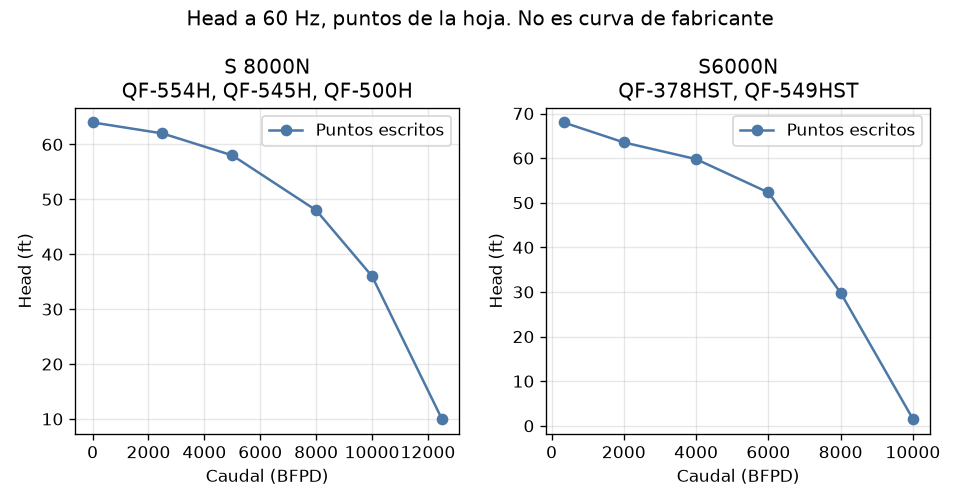

In [6]:
rutas = guardar_figuras(hojas, estaciones)
display(Image(filename=str(RAIZ / "reports" / "figuras" / "head_puntos_60hz.png")))

**Interpretación de la tabla y la figura.** Hay solo **dos curvas distintas**: la de `S 8000N` (idéntica valor a valor en `QF-554H`, `QF-545H` y `QF-500H`) y la de `S6000N` (`QF-378HST` y `QF-549HST`). Es decir, lo que cada hoja llama «curva de la bomba» describe a la **referencia de bomba**, no a cada pozo; ninguna fuente del expediente indica que esas tablas sean de fabricante (CT-06). En la figura ambas curvas son decrecientes y **cóncavas** (la altura cae cada vez más rápido al aumentar el caudal): `S 8000N` baja de 64 ft por etapa a 0 BFPD a 10 ft por etapa a 12 500 BFPD; `S6000N` baja de unos 68 ft por etapa cerca de 350 BFPD (su primer punto no está en cero) a ≈1.5 ft por etapa a 10 000 BFPD. **Consecuencia para el cálculo:** el caudal a producir se obtiene como la THD dividida entre la pendiente local de la curva, de modo que un tramo **plano** amplifica cualquier incertidumbre en la THD. Ejemplo medido en el cuaderno 05: un cambio de THD de ≈51 ft mueve el caudal 128 BFPD en `QF-554H` pero 456 BFPD en `QF-500H`, porque en esta última la intersección cae en un tramo mucho más plano de la curva.

## Paso 3 · Guardar las curvas y comprobar la relectura

**Qué se hace.** Se escribe la tabla en `data_procesados/curvas_bomba_60hz.csv` y se vuelve a leer. **Por qué.** Un CSV que no se relee es una promesa; el control compara lo leído con lo escrito, valor por valor (no basta con comparar el número de filas).

In [7]:
destino = RAIZ / "data_procesados" / "curvas_bomba_60hz.csv"
curvas.to_csv(destino, index=False)
relectura = pd.read_csv(destino)
iguales = relectura.shape == curvas.shape and bool((relectura.drop(columns=["hoja", "bomba", "eff_unidad_rotulo"]).to_numpy() == curvas.drop(columns=["hoja", "bomba", "eff_unidad_rotulo"]).to_numpy()).all()) \
          and bool((relectura[["hoja", "bomba", "eff_unidad_rotulo"]] == curvas[["hoja", "bomba", "eff_unidad_rotulo"]]).all().all())
print("Archivo:", destino.relative_to(RAIZ), "| filas:", len(relectura), "| relectura idéntica:", "SÍ" if iguales else "NO")

Archivo: data_procesados/curvas_bomba_60hz.csv | filas: 30 | relectura idéntica: SÍ


**Interpretación.** El archivo contiene las 30 filas, y la relectura es idéntica a la tabla en todos sus valores: ninguna transformación se coló entre la memoria y el disco.

## Paso 4 · Survey ordenado y contraste con el CSV existente

**Qué se hace.** Se ordena el survey (una fila por estación, con la hoja) y se compara, valor por valor, con `data_procesados/survey_estaciones.csv`, que ya existía de la primera versión del análisis. **No se reescribe** ese archivo: se **contrasta**. Además se comprueban las condiciones que necesitan los algoritmos posteriores: ningún faltante y MD estrictamente creciente por hoja.

In [8]:
survey = pd.DataFrame(estaciones)
csv_survey = pd.read_csv(RAIZ / "data_procesados" / "survey_estaciones.csv")
import numpy as np
coincide = (survey.shape == csv_survey.shape and list(survey.columns) == list(csv_survey.columns) and bool((survey["hoja"] == csv_survey["hoja"]).all())
            and bool(np.allclose(survey.drop(columns="hoja").to_numpy(float), csv_survey.drop(columns="hoja").to_numpy(float), rtol=0, atol=1e-9)))
cond = survey.groupby("hoja", sort=False).apply(lambda g: pd.Series({"estaciones": len(g), "faltantes": int(g.isna().sum().sum()),
        "MD repetidas": int(g.md_ft.duplicated().sum()), "MD creciente": bool(g.md_ft.is_monotonic_increasing)}), include_groups=False).reset_index()
print("Survey ordenado:", survey.shape, "| coincide con survey_estaciones.csv:", "SÍ" if coincide else "NO")
T(cond)

Survey ordenado: (321, 6) | coincide con survey_estaciones.csv: SÍ


hoja,estaciones,faltantes,MD repetidas,MD creciente
QF-554H,56,0,0,sí
QF-545H,68,0,0,sí
QF-500H,71,0,0,sí
QF-378HST,59,0,0,sí
QF-549HST,67,0,0,sí


In [9]:
T(pd.concat([survey[survey.hoja == "QF-554H"].head(3), survey[survey.hoja == "QF-554H"].tail(3)]), ancha=True)

hoja,md_ft,inclinacion_deg,azimut_deg,vertical_ft,dogleg_deg_por_100ft
QF-554H,0,0,0,0,0
QF-554H,437,0.35,294.02,437,0.08
QF-554H,570,0.25,319.34,570,0.12
QF-554H,4324,90.68,22.74,2892.38,0.82
QF-554H,4412,89.94,24.34,2891.9,2
QF-554H,4530,90,25,2891.96,0.56


**Interpretación.** El survey ordenado tiene 321 estaciones (56 a 71 por hoja), sin faltantes ni MD repetidas, y coincide valor a valor con el CSV existente. Las primeras filas de `QF-554H` muestran estaciones muy separadas (de 0 a 437 ft) con inclinación casi nula, es decir, el tramo vertical, y las últimas muestran inclinación de ≈90° con la profundidad vertical casi constante (≈2 892 ft): la sección horizontal. Los pasos entre estaciones tienen mediana de 63 a 81 ft pero llegan a 267–437 ft en el inicio de cada pozo; ahí la **interpolación lineal** de TVD entre estaciones es más gruesa, aunque en un tramo vertical la TVD coincide con la MD y el error es nulo. La interpolación importa realmente en la sección inclinada, donde están los equipos (MD ≈ 2 800–3 060 ft) y las estaciones están más próximas.

## Paso 5 · Estadísticas descriptivas

### 5.1 Entradas de operación entre los cinco pozos

**Qué se calcula.** Para cada entrada que varía se resumen los cinco valores: mínimo, máximo, media, mediana, desviación estándar muestral y coeficiente de variación (desviación/media). **Cómo leerlo.** Con n = 5 esto es una **descripción de estos cinco pozos**, no una estimación de una población: con tan pocos datos, la media y la desviación son inestables y los percentiles no tienen sentido (por eso no se calculan).

In [10]:
VARS = [("frecuencia_hz", "Frecuencia (Hz)"), ("etapas", "Etapas"), ("caudal_operacion_bfpd", "Caudal (BFPD)"), ("presion_sensor_psi", "Presión del sensor (psi)"),
        ("thp_psi", "THP (psi)"), ("temperatura_c", "Temperatura (°C)"), ("bsw_numero", "BS&W (número)")]
filas = []
for k, nombre in VARS:
    v = pd.Series([h[k] for h in hojas], dtype=float)
    filas.append({"variable": nombre, "n": len(v), "mínimo": v.min(), "máximo": v.max(), "media": v.mean(), "mediana": v.median(), "desv. estándar": v.std(ddof=1), "CV (%)": 100 * v.std(ddof=1) / v.mean()})
est_op = pd.DataFrame(filas)
T(est_op, ancha=True)

variable,n,mínimo,máximo,media,mediana,desv. estándar,CV (%)
Frecuencia (Hz),5,56,67,61,62,4.5276926,7.4224468
Etapas,5,31,53,40.2,36,10.568822,26.290602
Caudal (BFPD),5,5419,10301,7866.2,7728,1824.1696,23.189972
Presión del sensor (psi),5,607,821,727.4,732,91.854777,12.627822
THP (psi),5,145,210,181.8,183,24.097718,13.25507
Temperatura (°C),5,62.222222,65.555556,64.888889,65.555556,1.490712,2.2973301
BS&W (número),5,0.9557,0.9766,0.96558,0.9644,0.010203774,1.0567507


**Interpretación.** Las variables con más dispersión relativa entre pozos son las **etapas** (CV 26 %) y el **caudal** (23 %), seguidas por el THP (13 %) y la presión del sensor (13 %); la frecuencia varía 7 % y la temperatura y el BS&W apenas 2 % y 1 %. Con n = 5 estos coeficientes describen la heterogeneidad **de esta muestra** (pozos con distinta bomba y producción) y no sirven para inferir nada sobre otros pozos. Importa lo que no varía: con un CV de 1–2 %, la temperatura y el BS&W no permiten estudiar su influencia con estos datos (el cuaderno 04 mide cuánto pesarían si cambiaran). La media de la frecuencia (61 Hz) está muy cerca de los 60 Hz de la curva: los cinco pozos operan alrededor de la frecuencia nominal, entre −7 % y +12 %.

### 5.2 Estadísticas del survey por pozo

Se resumen, por hoja, la profundidad medida, la inclinación y la severidad (dogleg). Aquí sí hay entre 56 y 71 observaciones por hoja y los cuartiles son informativos; sin embargo, las estaciones **no son muestras independientes** (son puntos consecutivos de una trayectoria), de modo que estas estadísticas describen la **forma** de la trayectoria y no una variabilidad aleatoria.

In [11]:
st = pd.DataFrame(tabla_survey(estaciones))
sel = st[st["variable"].isin(["md_ft", "inclinacion_deg", "dogleg_deg_por_100ft"])][["hoja", "variable", "n", "minimo", "p25", "mediana", "p75", "maximo", "media", "desviacion_estandar"]]
T(sel, ancha=True)

hoja,variable,n,minimo,p25,mediana,p75,maximo,media,desviacion_estandar
QF-554H,md_ft,56,0,1486.5,2332.5,3292,4530,2391.625,1162.4855
QF-554H,inclinacion_deg,56,0,9.8375,31.12,75.835,90.68,40.423571,33.922822
QF-554H,dogleg_deg_por_100ft,56,0,0.6625,2.01,4.8325,6.86,2.7123214,2.2856557
QF-545H,md_ft,68,0,1297.75,2339.5,3370.75,4576,2346.7647,1260.8311
QF-545H,inclinacion_deg,68,0,12.7175,46.425,73.36,91.5,45.552941,31.523454
QF-545H,dogleg_deg_por_100ft,68,0,1.64,2.615,3.8475,4.98,2.7360294,1.4174553
QF-500H,md_ft,71,0,1310.5,2380,3477,4637,2391.3662,1298.1561
QF-500H,inclinacion_deg,71,0,9.72,39.34,85.46,90.8,43.867465,34.756551
QF-500H,dogleg_deg_por_100ft,71,0,0.855,1.96,4.805,6.44,2.5787324,2.0632394
QF-378HST,md_ft,59,0,1457,2351,3257,4598,2369.2034,1231.0233


**Interpretación.** La mediana de MD está entre 2 332 y 2 380 ft y el máximo entre 4 530 y 4 637 ft; la inclinación tiene mediana de 28° a 46° y tercer cuartil de 62° a 85°, con máximos de 90.5° a 91.5°; la severidad media es de 2.6 a 3.7 °/100 ft y la máxima de 8.35 °/100 ft se da en `QF-378HST`, la más severa de las cinco. **Advertencia de lectura:** la media de la inclinación (39° a 46°) no representa ninguna parte real del pozo, porque la trayectoria pasa de vertical a horizontal; presentar «la inclinación media del pozo» sería engañoso. Lo informativo son los cuartiles y la forma de las figuras del cuaderno de inspección.

## Paso 6 · Criterios de aceptación

In [12]:
crit = Criterios("03_mapeo_y_preparacion_BES_jun")
crit.comprobar("C03b-1", "6 puntos de curva por hoja (30 en total)", len(curvas) == 30 and bool((orden["puntos"] == 6).all()), f"{len(curvas)} filas")
crit.comprobar("C03b-2", "Caudal creciente y altura decreciente en cada curva", bool(orden["caudal creciente"].all() and orden["altura decreciente"].all()), "5/5 hojas")
crit.comprobar("C03b-3", "CSV de curvas releído idéntico", iguales, destino.name)
crit.comprobar("C03b-4", "Survey ordenado coincide con survey_estaciones.csv", bool(coincide), f"{len(survey)} estaciones")
crit.comprobar("C03b-5", "Survey sin faltantes ni MD repetidas", bool((cond["faltantes"] == 0).all() and (cond["MD repetidas"] == 0).all() and cond["MD creciente"].all()), "5/5 hojas")
crit.comprobar("C03b-6", "La figura de curvas existe", (RAIZ / "reports" / "figuras" / "head_puntos_60hz.png").is_file(), "head_puntos_60hz.png")
crit.comprobar("C03b-7", "El libro no cambió", huellas(COPIA_TRABAJO)["sha256"] == sha_inicial, sha_inicial[:16] + "…")
T(crit.tabla())

id,criterio,resultado,evidencia
C03b-1,6 puntos de curva por hoja (30 en total),CUMPLE,30 filas
C03b-2,Caudal creciente y altura decreciente en cada curva,CUMPLE,5/5 hojas
C03b-3,CSV de curvas releído idéntico,CUMPLE,curvas_bomba_60hz.csv
C03b-4,Survey ordenado coincide con survey_estaciones.csv,CUMPLE,321 estaciones
C03b-5,Survey sin faltantes ni MD repetidas,CUMPLE,5/5 hojas
C03b-6,La figura de curvas existe,CUMPLE,head_puntos_60hz.png
C03b-7,El libro no cambió,CUMPLE,ccb5a738baea1332…


In [13]:
crit.exigir()
print("Todos los criterios de aceptación del cuaderno 03 (preparación) se cumplen.")

Todos los criterios de aceptación del cuaderno 03 (preparación) se cumplen.


## Conclusión técnica

- **Resultado:** quedan dos tablas ordenadas y verificadas (30 puntos de curva y 321 estaciones de survey) sin ninguna transformación de valores, con las condiciones de orden que necesitan los algoritmos (altura decreciente, MD creciente) comprobadas.
- **Hallazgo principal:** las curvas de bomba son solo dos y están repetidas entre pozos; describen referencias de bomba y no pozos individuales (H-09 / CT-06).
- **Qué enseñan las estadísticas:** la muestra es heterogénea en etapas y caudal y casi uniforme en temperatura y BS&W; con n = 5 son descriptivas.
- **Qué no se hace:** limpiar, imputar o eliminar atípicos; no había nada que corregir.
- **Siguiente paso:** `03_limpieza_y_mapeo`, cuya tabla larga complementa estas dos estructuras con las entradas del formulario.

## Relación con el sistema de reglas

Prepara la curva de seis puntos que consume `M-BES-INTERSECCION`. La curva es una tabla escrita a 60 Hz, no una serie de ensayos. Unidad: BFPD y ft, como en la hoja.

## Limitaciones

- Las tablas ordenadas (survey y curvas de bomba) son copias fieles; las estadísticas son **descriptivas** con n = 5 hojas y 6 puntos por curva.
- No se eliminan valores atípicos ni se rellenan faltantes.
- Las curvas de bomba están repetidas entre pozos (hallazgo H-09); la estadística por pozo no equivale a una caracterización de cada bomba.
- Los gráficos usan la escala natural de cada variable y no se comparan entre sí.

## Referencias

Solo se listan las fuentes realmente consultadas en este cuaderno.

1. **Libro de trabajo:** `entrada/BES_jun.xlsx`, copia byte a byte de «Copia de FINAL BES-jun.xlsx» (SHA-256 `ccb5a738baea13321993e8b6eccefd6cac90ecda86b1c4b9181f897fcfa83f85`). Cinco hojas: QF-554H, QF-545H, QF-500H, QF-378HST y QF-549HST.
2. **`docs/consultas_tecnicas_pendientes.md`** (expediente): registro CT-01…CT-10 de ambigüedades abiertas.
3. **Software:** Python 3.14.8, pandas 3.0.6, numpy 2.5.4, matplotlib 3.11.2, openpyxl 3.1.5 (versiones tomadas de la ficha de entorno de cada ejecución).